In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.tri as tri
import sys
from matplotlib import path
from matplotlib import cm, ticker
import scipy as sc

In [2]:
all_parameters = []
alle_arrays = []

with open("Grid_search_ellipses_5_all_Eigenvalues_nodal_line_detection_1_1_1/Results_from_files", "r", encoding="utf-8") as f:
    for zeile in f:
        teile = zeile.strip().split()
        liste = [float(teile[0]), float(teile[1]), float(teile[2])]

        if teile[3] == "True":
            liste.append(0)
        elif teile[3] == "False":
            liste.append(1)
        else:
            liste.append(-1)

        rest_array = np.array([complex(x) for x in teile[4:]])

        all_parameters.append(liste)
        alle_arrays.append(rest_array)

all_parameters = np.array(all_parameters)

In [3]:
all_parameters_before = np.copy(all_parameters)

In [4]:
Moore_5_1_02_1 = pd.read_csv("Moore_neighbor_5_1_02_1/Parameters_Eigenvalues.csv")
Moore_5_1_02_1

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.01,0.54,1.02,False,0,0j,False
1,[0.01],[0.52],1.02,False,0,0j,False
2,[0.01],[0.52],1.02,False,[3.36144239-5.00180253e-09j 3.4073493 -2.85201...,(2.2438970810655174-2.5597284292189215e-09j),True
3,[0.03],[0.52],1.02,False,0,0,False
4,[0.03],[0.52],1.02,False,[3.40826826-5.15442673e-09j 3.45760123+9.03067...,(2.2826864765874277-6.646816430588842e-11j),True
...,...,...,...,...,...,...,...
66,[0.09],[0.68],1.02,False,[3.74295986-1.66738756e-09j 3.79275691-7.32388...,(2.432905651044545+9.450218385609332e-13j),False
67,0.09,0.7000000000000002,1.02,False,0,0,True
68,[0.07],[0.7],1.02,False,0,0,False
69,[0.07],[0.7],1.02,False,[3.69315582-9.91470417e-09j 3.74237182-7.19670...,(2.386701572287602+2.9807267765136203e-12j),False


In [5]:
Moore_5_1_02 = []

In [6]:
Moore_5_1_02_1 = pd.read_csv("Moore_neighbor_5_1_02_1/Parameters_Eigenvalues.csv")
Moore_5_1_02.append(Moore_5_1_02_1[:20:2])

In [7]:
Moore_5_1_02_1[69::2]

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
69,[0.07],[0.7],1.02,False,[3.69315582-9.91470417e-09j 3.74237182-7.19670...,(2.386701572287602+2.9807267765136203e-12j),False


In [8]:
Moore_5_1_02.append(Moore_5_1_02_1[21:63:2])

In [9]:
Moore_5_1_02.append(Moore_5_1_02_1[64:67:2])

In [10]:
Moore_5_1_02.append(Moore_5_1_02_1[69:70:2])

In [11]:
Moore_5_1_02_2 = pd.read_csv("Moore_neighbor_5_1_02_2/Parameters_Eigenvalues.csv")
Moore_5_1_02_2

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.07,0.7,1.02,False,0,0j,False
1,[0.05],[0.72],1.02,False,0,0j,False
2,[0.05],[0.72],1.02,False,[3.64144587-9.47250722e-09j 3.69030824-7.30358...,(2.3421356353036806-2.0294876890147862e-13j),True
3,[0.05],[0.7],1.02,False,0,0,False
4,[0.05],[0.7],1.02,False,[3.63181764-5.65843949e-09j 3.68180226-8.11162...,(2.341418293195313+5.417888360170764e-14j),False
5,0.05,0.72,1.02,False,0,0,True
6,[0.03],[0.72],1.02,False,0,0,False
7,[0.03],[0.72],1.02,False,[3.58143499-6.39279163e-09j 3.63115268-6.39673...,(2.298724550271353+2.1313617537543905e-11j),True
8,[0.03],[0.7],1.02,False,0,0,False
9,[0.03],[0.7],1.02,False,[3.57295728-6.49141230e-09j 3.62373991-4.15030...,(2.2982653483364226-2.4429347433851945e-12j),False


In [12]:
Moore_5_1_02.append(Moore_5_1_02_2[2:5:2])

In [13]:
Moore_5_1_02.append(Moore_5_1_02_2[7:11:2])

In [14]:
Moore_5_1_02.append(Moore_5_1_02_2[12:13])

In [15]:
Moore_5_1_02 = pd.concat(Moore_5_1_02, axis=0, ignore_index=True)
Moore_5_1_02

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.01,0.54,1.02,False,0,0j,False
1,[0.01],[0.52],1.02,False,[3.36144239-5.00180253e-09j 3.4073493 -2.85201...,(2.2438970810655174-2.5597284292189215e-09j),True
2,[0.03],[0.52],1.02,False,[3.40826826-5.15442673e-09j 3.45760123+9.03067...,(2.2826864765874277-6.646816430588842e-11j),True
3,[0.03],[0.54],1.02,False,[3.43471805-5.13907925e-09j 3.48737533-6.47025...,(2.286346046753177+1.5422330079672975e-11j),True
4,[0.03],[0.56],1.02,False,[3.45913375-5.25412772e-09j 3.5138576 -9.70972...,(2.2893063056815124-8.482103908136196e-14j),False
5,[0.05],[0.54],1.02,False,[3.48421709-5.90863926e-09j 3.53845501+1.54074...,(2.327381436812954+9.070788564713439e-11j),True
6,[0.05],[0.56],1.02,False,[3.5099156 -6.45543796e-09j 3.56554076-3.95232...,(2.330567406923445-1.6768808563938364e-11j),True
7,[0.05],[0.58],1.02,False,[3.53347981-5.96544293e-09j 3.58955054-5.73520...,(2.3331791452106136+2.3596680165383077e-11j),False
8,[0.07],[0.56],1.02,False,[3.5622659 -4.47140198e-09j 3.61814633-2.23609...,(2.374002343170683+1.1330936189324348e-11j),True
9,[0.07],[0.58],1.02,False,[3.58721391-2.71150258e-09j 3.64315171-5.42515...,(2.3768632920357713+1.070921129553426e-11j),False


In [16]:
Moore_5_1_04 = []
Moore_5_1_04_1 = pd.read_csv("Moore_neighbor_5_1_04_1/Parameters_Eigenvalues.csv")

In [17]:
Moore_5_1_04.append(Moore_5_1_04_1[:19:2])

In [18]:
Moore_5_1_04.append(Moore_5_1_04_1[21:37:2])

In [19]:
Moore_5_1_04.append(Moore_5_1_04_1[38:53:2])

In [20]:
Moore_5_1_04.append(Moore_5_1_04_1[55:68:2])

In [21]:
Moore_5_1_04.append(Moore_5_1_04_1[70::2])

In [22]:
Moore_5_1_04_2 = pd.read_csv("Moore_neighbor_5_1_04_2/Parameters_Eigenvalues.csv")
Moore_5_1_04_2[40:60]

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
40,[0.21],[0.69],1.04,False,0,0,False
41,[0.21],[0.69],1.04,False,[4.29020158-7.31315797e-09j 4.29122775-1.91335...,(2.705431390911082+0j),True
42,[0.21],[0.67],1.04,False,0,0,False
43,[0.21],[0.67],1.04,False,[4.26076933+7.64545867e-10j 4.28617301-3.08995...,(2.7027267906426777+4.440892098500626e-16j),False
44,0.21000000000000002,0.6900000000000001,1.04,False,0,0,True
45,[0.19],[0.69],1.04,False,0,0,False
46,[0.19],[0.69],1.04,False,[4.19527164+2.11351549e-07j 4.19527225-7.03377...,(2.644510501077869+1.1102230246251565e-15j),True
47,[0.19],[0.67],1.04,False,0,0,False
48,[0.19],[0.67],1.04,False,[4.18145239-1.36998063e-08j 4.19058774+5.42174...,(2.641999124992601+4.440892098500626e-16j),False
49,0.19000000000000003,0.6900000000000001,1.04,False,0,0,True


In [23]:
Moore_5_1_04.append(Moore_5_1_04_2[2:19:2])

In [24]:
Moore_5_1_04.append(Moore_5_1_04_2[21:24:2])

In [25]:
Moore_5_1_04.append(Moore_5_1_04_2[26:38:2])

In [26]:
Moore_5_1_04.append(Moore_5_1_04_2[39:45:2])

In [27]:
Moore_5_1_04.append(Moore_5_1_04_2[46:49:2])

In [28]:
Moore_5_1_04.append(Moore_5_1_04_2[51:60:2])

In [29]:
Moore_5_1_04.append(Moore_5_1_04_2[62::2])

In [30]:
Moore_5_1_04_3 = pd.read_csv("Moore_neighbor_5_1_04_3/Parameters_Eigenvalues.csv")
Moore_5_1_04_3

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.15,0.65,1.04,False,0,0j,False
1,[0.13],[0.63],1.04,False,0,0j,False
2,[0.13],[0.63],1.04,False,[3.91122354-8.17503938e-09j 3.92303174-1.49973...,(2.472803600774814-4.973799150320701e-14j),False
3,[0.11],[0.65],1.04,False,0,0,False
4,[0.11],[0.65],1.04,False,[3.85008861+4.11387391e-09j 3.85008862+1.80739...,(2.425750096758571-7.416289804496046e-14j),True
5,[0.11],[0.63],1.04,False,0,0,False
6,[0.11],[0.63],1.04,False,[3.84538209-5.94884944e-09j 3.84587516+5.36896...,(2.4236158468599887+1.4876988529977098e-13j),False
7,0.11,0.65,1.04,False,0,0,True
8,[0.09],[0.65],1.04,False,0,0,False
9,[0.09],[0.65],1.04,False,[3.77630092-8.83128943e-11j 3.77630092+3.45846...,(2.3787097075616916-3.126388037344441e-13j),True


In [31]:
Moore_5_1_04.append(Moore_5_1_04_3[2:8:2])

In [32]:
Moore_5_1_04.append(Moore_5_1_04_3[9::2])

In [33]:
Moore_5_1_04_4 = pd.read_csv("Moore_neighbor_5_1_04_4/Parameters_Eigenvalues.csv")
Moore_5_1_04_4

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.11,0.63,1.04,False,0,0j,False
1,[0.09],[0.61],1.04,False,0,0j,False
2,[0.09],[0.61],1.04,False,[3.75868745-5.62001596e-09j 3.76729839-5.75956...,(2.374627679242415-8.58424442640171e-13j),False
3,[0.07],[0.63],1.04,False,0,0,False
4,[0.07],[0.63],1.04,False,[3.7026227 -5.37354899e-10j 3.7026227 +1.17535...,(2.3322902847458717+8.135714324453147e-13j),True
5,[0.07],[0.61],1.04,False,0,0,False
6,[0.07],[0.61],1.04,False,[3.69774008-4.39670522e-11j 3.69774008-7.95992...,(2.3303486569962035-4.6704862199931085e-12j),True
7,[0.07],[0.59],1.04,False,0,0,False
8,[0.07],[0.59],1.04,False,[3.67499123-6.69038781e-09j 3.68971688-7.52891...,(2.3280368433799-9.325873406851315e-14j),False
9,[0.05],[0.61],1.04,False,0,0,False


In [34]:
Moore_5_1_04.append(Moore_5_1_04_4[2:14:2])

In [35]:
Moore_5_1_04.append(Moore_5_1_04_4[15::2])

In [36]:
Moore_5_1_04 = pd.concat(Moore_5_1_04, axis=0, ignore_index=True)
Moore_5_1_04

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.01,0.51,1.04,False,0,0j,False
1,[0.01],[0.49],1.04,False,[3.37354068-3.00943814e-09j 3.37354068-3.34261...,(2.191422930149308-5.52153434085767e-10j),True
2,[0.03],[0.49],1.04,False,[3.42518287-5.24022686e-09j 3.42980172-3.85308...,(2.2283689206803476+3.3593128279107987e-12j),False
3,[0.01],[0.47],1.04,False,[3.33351151-3.24772964e-09j 3.33351151-3.55506...,(2.185460972166059+3.833641667437638e-09j),True
4,[0.03],[0.47],1.04,False,[3.38858327-4.91808994e-09j 3.38858328-2.90231...,(2.2222969528430654-8.318878919055805e-10j),True
...,...,...,...,...,...,...,...
76,[0.03],[0.59],1.04,False,[3.56050425+1.25271622e-10j 3.56050426-3.83049...,(2.2463361759838514+9.383160914921973e-12j),True
77,[0.03],[0.57],1.04,False,[3.54045135-5.91827001e-09j 3.54741878+3.03571...,(2.2440506593202447-6.993161605350906e-11j),False
78,[0.01],[0.59],1.04,False,[3.50001623+5.80552203e-10j 3.50001625-7.37845...,(2.208465917135815+2.1410651029896144e-10j),True
79,[0.01],[0.57],1.04,False,[3.48701622+3.39211158e-09j 3.48701624-6.03709...,(2.2064091832878576-7.008482683090733e-11j),True


In [37]:
Moore_5_1_06 = []
Moore_5_1_06_1 = pd.read_csv("Moore_neighbor_5_1_06_1/Parameters_Eigenvalues.csv")
Moore_5_1_06_1

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,[0.2],[0.48],1.06,False,0,0j,False
1,[0.2],[0.48],1.06,False,[3.88885916-5.29055478e-09j 4.00808361-4.63549...,(2.563747054909053-7.452705119703751e-12j),True
2,[0.21],[0.48],1.06,False,0,0,False
3,[0.21],[0.48],1.06,False,[3.91315582-1.02635055e-08j 3.93672875-5.92702...,(2.5919515088251583-6.701306176637445e-12j),True
4,[0.21],[0.49],1.06,False,0,0,False
5,[0.21],[0.49],1.06,False,[3.94225883-9.74647657e-09j 3.9678222 -8.34392...,(2.5957514199987517-5.199840558134383e-12j),False
6,[0.22],[0.48],1.06,False,0,0,False
7,[0.22],[0.48],1.06,False,[3.93716299-1.04646260e-08j 3.96145526-2.13178...,(2.620911216134927-5.984990281149294e-12j),True
8,[0.22],[0.49],1.06,False,0,0,False


In [38]:
# Ist schon in 6_1_06_2 und muss deshalb nicht mit rein
Moore_5_1_06_1[1::2]

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
1,[0.2],[0.48],1.06,False,[3.88885916-5.29055478e-09j 4.00808361-4.63549...,(2.563747054909053-7.452705119703751e-12j),True
3,[0.21],[0.48],1.06,False,[3.91315582-1.02635055e-08j 3.93672875-5.92702...,(2.5919515088251583-6.701306176637445e-12j),True
5,[0.21],[0.49],1.06,False,[3.94225883-9.74647657e-09j 3.9678222 -8.34392...,(2.5957514199987517-5.199840558134383e-12j),False
7,[0.22],[0.48],1.06,False,[3.93716299-1.04646260e-08j 3.96145526-2.13178...,(2.620911216134927-5.984990281149294e-12j),True


In [39]:
Moore_5_1_06_2 = pd.read_csv("Moore_neighbor_5_1_06_2/Parameters_Eigenvalues.csv")
Moore_5_1_06_2

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.2,0.49,1.06,False,0,0j,False
1,[0.2],[0.48],1.06,False,0,0j,False
2,[0.2],[0.48],1.06,False,[3.88885916-9.17485736e-09j 3.9107314 -8.37838...,(2.563747054909043-7.496669951478907e-12j),True
3,[0.21],[0.48],1.06,False,0,0,False
4,[0.21],[0.48],1.06,False,[3.91315582-7.80368063e-09j 3.93672841+1.84361...,(2.5919515088252534-6.6422423117273866e-12j),True
5,[0.21],[0.49],1.06,False,0,0,False
6,[0.21],[0.49],1.06,False,[3.94225883-9.65475443e-09j 3.96782219-2.77758...,(2.5957514199987495-5.086153720412767e-12j),False
7,0.21000000000000002,0.48,1.06,False,0,0,True
8,[0.22],[0.48],1.06,False,0,0,False
9,[0.22],[0.48],1.06,False,[3.93716299-9.73070138e-09j 3.96145526-3.58210...,(2.620911216134991-6.055156376305604e-12j),True


In [40]:
Moore_5_1_06.append(Moore_5_1_06_2[:7:2])

In [41]:
Moore_5_1_06.append(Moore_5_1_06_2[9:16:2])

In [42]:
Moore_5_1_06.append(Moore_5_1_06_2[18:24:2])

In [43]:
Moore_5_1_06.append(Moore_5_1_06_2[25:40:2])

In [44]:
Moore_5_1_06.append(Moore_5_1_06_2[42::2])

In [45]:
Moore_5_1_06_3 = pd.read_csv("Moore_neighbor_5_1_06_3/Parameters_Eigenvalues.csv")
Moore_5_1_06_3

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.2,0.49,1.06,False,0,0j,False
1,[0.21],[0.5],1.06,False,0,0j,False
2,[0.21],[0.5],1.06,False,[3.97102727-1.07576853e-08j 3.99831242-8.49303...,(2.5993395443236755-3.844480289671992e-12j),False
3,[0.22],[0.49],1.06,False,0,0,False
4,[0.22],[0.49],1.06,False,[3.96702993-1.03630183e-08j 3.99323838-9.53787...,(2.624768702067577-4.53725945703809e-12j),True
5,[0.22],[0.5],1.06,False,0,0,False


In [46]:
Moore_5_1_06.append(Moore_5_1_06_3[2::2])

In [47]:
Moore_5_1_06_4 = pd.read_csv("Moore_neighbor_5_1_06_4/Parameters_Eigenvalues.csv")
Moore_5_1_06_4

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.28,0.55,1.06,False,0,0j,False
1,[0.29],[0.56],1.06,False,0,0j,False
2,[0.29],[0.56],1.06,False,[4.37208052-1.65913037e-08j 4.39764669-3.60934...,(2.8760554635092737-7.771561172376096e-14j),False
3,[0.3],[0.55],1.06,False,0,0,False
4,[0.3],[0.55],1.06,False,[4.36474857-1.76072213e-08j 4.38749496-3.49608...,(2.909519136646072-6.110312256168982e-11j),True
5,[0.3],[0.56],1.06,False,0,0,False
6,[0.3],[0.56],1.06,False,[4.39975725-1.77430456e-08j 4.42327562+2.70548...,(2.9126016120892646+2.049738156983949e-11j),True
7,[0.3],[0.57],1.06,False,0,0,False
8,[0.3],[0.57],1.06,False,[4.43444985-1.78819450e-08j 4.45876081-1.16628...,(2.9155411827071513-1.3774759111129242e-11j),False
9,[0.31],[0.56],1.06,False,0,0,False


In [48]:
Moore_5_1_06.append(Moore_5_1_06_4[2:37:2])

In [49]:
Moore_5_1_06.append(Moore_5_1_06_4[39::2])

In [50]:
Moore_5_1_06_5 = pd.read_csv("Moore_neighbor_5_1_06_5/Parameters_Eigenvalues.csv")
Moore_5_1_06_5

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.36,0.6,1.06,False,0,0j,False
1,[0.38],[0.62],1.06,False,0,0j,False
2,[0.38],[0.62],1.06,False,[4.85618168-1.15807609e-07j 4.868102 +1.25630...,(3.2648253822593745+2.5432989048113086e-12j),True
3,[0.36],[0.62],1.06,False,0,0,False
4,[0.36],[0.62],1.06,False,[4.81315298+1.53392854e-07j 4.81315803-1.53889...,(3.173124075337013+3.526068326209497e-13j),True
...,...,...,...,...,...,...,...
58,[0.18],[0.54],1.06,False,0,0,False
59,[0.18],[0.54],1.06,False,[3.99235304-1.05735984e-06j 3.99235468+5.33903...,(2.5283583066772803-1.6795453916529368e-12j),True
60,[0.18],[0.52],1.06,False,0,0,False
61,[0.18],[0.52],1.06,False,[3.94443415-2.27926232e-08j 3.96013888-4.65562...,(2.522813801216135-3.1592506388733455e-12j),False


In [51]:
Moore_5_1_06.append(Moore_5_1_06_5[2:11:2])

In [52]:
Moore_5_1_06.append(Moore_5_1_06_5[13:26:2])

In [53]:
Moore_5_1_06.append(Moore_5_1_06_5[28:37:2])

In [54]:
Moore_5_1_06.append(Moore_5_1_06_5[39::2])

In [55]:
Moore_5_1_06_6 = pd.read_csv("Moore_neighbor_5_1_06_6/Parameters_Eigenvalues.csv")
Moore_5_1_06_6

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.18,0.52,1.06,False,0,0j,False
1,[0.16],[0.54],1.06,False,0,0j,False
2,[0.16],[0.54],1.06,False,[3.91213544-4.32438026e-06j 3.91218678-5.92115...,(2.476209867088892-2.247535491051167e-12j),True
3,[0.16],[0.52],1.06,False,0,0,False
4,[0.16],[0.52],1.06,False,[3.88708633-3.91064566e-09j 3.88708637-8.98959...,(2.4708867209537884-3.938183112950355e-12j),True
5,[0.16],[0.5],1.06,False,0,0,False
6,[0.16],[0.5],1.06,False,[3.84008011-8.26509747e-09j 3.84738969-5.30750...,(2.4648514907331815-6.795897178335508e-12j),False
7,[0.14],[0.52],1.06,False,0,0,False
8,[0.14],[0.52],1.06,False,[3.81302797-1.47086743e-09j 3.81302797-2.41307...,(2.4215517278278664-5.0532911188838625e-12j),True
9,[0.14],[0.5],1.06,False,0,0,False


In [56]:
Moore_5_1_06.append(Moore_5_1_06_6[2:15:2])

In [57]:
Moore_5_1_06.append(Moore_5_1_06_6[17:20:2])

In [58]:
Moore_5_1_06.append(Moore_5_1_06_6[22::2])

In [59]:
Moore_5_1_06 = pd.concat(Moore_5_1_06, axis=0, ignore_index=True)
Moore_5_1_06

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.2,0.49,1.06,False,0,0j,False
1,[0.2],[0.48],1.06,False,[3.88885916-9.17485736e-09j 3.9107314 -8.37838...,(2.563747054909043-7.496669951478907e-12j),True
2,[0.21],[0.48],1.06,False,[3.91315582-7.80368063e-09j 3.93672841+1.84361...,(2.5919515088252534-6.6422423117273866e-12j),True
3,[0.21],[0.49],1.06,False,[3.94225883-9.65475443e-09j 3.96782219-2.77758...,(2.5957514199987495-5.086153720412767e-12j),False
4,[0.22],[0.48],1.06,False,[3.93716299-9.73070138e-09j 3.96145526-3.58210...,(2.620911216134991-6.055156376305604e-12j),True
...,...,...,...,...,...,...,...
96,[0.16],[0.44],1.06,False,[3.68233468-6.99216213e-09j 3.68233473+2.54096...,(2.4414983422566707-2.2854607095723622e-11j),True
97,[0.18],[0.44],1.06,False,[3.72924977+2.42185103e-07j 3.73499934+2.85774...,(2.4925833265897768-1.8464341167145903e-11j),True
98,[0.18],[0.46],1.06,False,[3.78484121+6.49388770e-08j 3.7969037 -2.99909...,(2.50155052384117-1.41824330057716e-11j),True
99,[0.18],[0.48],1.06,False,[3.83955876+7.41889949e-09j 3.8563569 +8.85340...,(2.5095073114299544-9.00524099733957e-12j),False


In [60]:
Moore_5_1_08 = []
Moore_5_1_08_1 = pd.read_csv("Moore_neighbor_5_1_08_1/Parameters_Eigenvalues.csv")
Moore_5_1_08_1

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.3,0.51,1.08,False,0,0j,False
1,[0.3],[0.49],1.08,False,0,0j,False
2,[0.3],[0.49],1.08,False,[4.20696659-1.82869505e-08j 4.21914057-2.06994...,(2.8103936950671544-2.3516744107610066e-12j),True
3,[0.32],[0.49],1.08,False,0,0,False
4,[0.32],[0.49],1.08,False,[4.24547876-2.01477727e-08j 4.25621478-2.04982...,(2.8817128838599073-1.7628121184998236e-12j),True
...,...,...,...,...,...,...,...
59,[0.24],[0.51],1.08,False,0,0,False
60,[0.24],[0.51],1.08,False,[4.12738759+5.18878842e-07j 4.1273895 +7.73006...,(2.6258768619824617-2.8061997170425457e-12j),True
61,[0.24],[0.49],1.08,False,0,0,False
62,[0.24],[0.49],1.08,False,[4.07507889+1.45154425e-05j 4.07509294+1.59079...,(2.618513416648551-5.0741633117468155e-12j),True


In [61]:
Moore_5_1_08.append(Moore_5_1_08_1[:33:2])

In [62]:
Moore_5_1_08.append(Moore_5_1_08_1[35:38:2])

In [63]:
Moore_5_1_08.append(Moore_5_1_08_1[40::2])

In [64]:
Moore_5_1_08_2 = pd.read_csv("Moore_neighbor_5_1_08_2/Parameters_Eigenvalues.csv")
Moore_5_1_08_2

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.26,0.51,1.08,False,0,0j,False
1,[0.26],[0.49],1.08,False,0,0j,False
2,[0.26],[0.49],1.08,False,[4.12297391-1.48629577e-08j 4.13193291-1.57295...,(2.6790527952120438-3.987477015243712e-12j),False
3,[0.24],[0.49],1.08,False,0,0,False
4,[0.24],[0.49],1.08,False,[4.07509236+1.32018678e-06j 4.07509296-1.46324...,(2.6185134166486397-5.079048293055166e-12j),True
5,[0.24],[0.47],1.08,False,0,0,False
6,[0.24],[0.47],1.08,False,[4.00815613+6.59136180e-07j 4.00817622-1.25422...,(2.610310987839432-8.701928067011977e-12j),True
7,[0.26],[0.47],1.08,False,0,0,False
8,[0.26],[0.47],1.08,False,[4.05124927-1.44631497e-08j 4.05794513+1.34092...,(2.670616555262958-7.068789997788372e-12j),True
9,[0.28],[0.47],1.08,False,0,0,False


In [65]:
Moore_5_1_08.append(Moore_5_1_08_2[2::2])

In [66]:
Moore_5_1_08 = pd.concat(Moore_5_1_08, axis=0, ignore_index=True)
Moore_5_1_08

,a,b,distance,Failed,second_eig,first_eig,touches_boundary
0,0.3,0.51,1.08,False,0,0j,False
1,[0.3],[0.49],1.08,False,[4.20696659-1.82869505e-08j 4.21914057-2.06994...,(2.8103936950671544-2.3516744107610066e-12j),True
2,[0.32],[0.49],1.08,False,[4.24547876-2.01477727e-08j 4.25621478-2.04982...,(2.8817128838599073-1.7628121184998236e-12j),True
3,[0.32],[0.51],1.08,False,[4.326302 -2.13716654e-08j 4.33842411-2.47684...,(2.8900391848641127-8.171241461241152e-13j),True
4,[0.32],[0.53],1.08,False,[4.40748147-2.23776489e-08j 4.42086283-2.71503...,(2.897597213056654-3.461675390781238e-13j),False
5,[0.34],[0.51],1.08,False,[4.36531401-2.34930147e-08j 4.37519336-2.14288...,(2.965775767504533+6.664402363298905e-11j),True
6,[0.34],[0.53],1.08,False,[4.44972072-2.52996370e-08j 4.4604829 +2.23217...,(2.9735828298605917-4.0104808363139455e-11j),True
7,[0.34],[0.55],1.08,False,[4.53459644-2.69022590e-08j 4.54624925+2.12827...,(2.9806943514614677-1.411271099982514e-11j),False
8,[0.36],[0.53],1.08,False,[4.48931213-1.05461023e-07j 4.49766056+6.71475...,(3.054078709758962-4.738565095863123e-11j),True
9,[0.36],[0.55],1.08,False,[4.57763719-4.64483383e-08j 4.58659518-1.32471...,(3.0614345985446003-8.945288954009811e-12j),True


In [67]:
def parse(x):
    return float(str(x).strip("[]"))
arr_correct_order = np.empty((1,3))
solution_all = np.array((1,1))
all_parameters = np.empty((1,4))
folders = [Moore_5_1_02, Moore_5_1_04, Moore_5_1_06, Moore_5_1_08]#, "Moore_neighbor_5_1_02_2", "Moore_neighbor_5_1_04_1", "Moore_neighbor_5_1_04_2", "Moore_neighbor_5_1_04_3", "Moore_neighbor_5_1_04_4", "Moore_neighbor_5_1_06_1", "Moore_neighbor_5_1_06_2", "Moore_neighbor_5_1_06_3", "Moore_neighbor_5_1_06_4", "Moore_neighbor_5_1_06_5", "Moore_neighbor_5_1_06_6", "Moore_neighbor_5_1_08_1", "Moore_neighbor_5_1_08_2"]
for folder in folders:
    arr =  folder.iloc[:, :3].applymap(parse).to_numpy()
    arr_correct_order_temp = arr[:,[2,0,1]]
    check_failed = folder['Failed'].to_numpy()
    check_touches_boundary = folder['touches_boundary'].to_numpy()
    solution = np.zeros(check_failed.shape)
    solution[check_failed] = -1
    solution[~check_failed & check_touches_boundary] = 0
    solution[~check_failed & ~check_touches_boundary] = 1
    all_parameters_temp = np.column_stack((arr_correct_order_temp, solution))
    print(all_parameters_temp)
    all_parameters = np.vstack((all_parameters, all_parameters_temp))

[[1.02 0.01 0.54 1.  ]
 [1.02 0.01 0.52 0.  ]
 [1.02 0.03 0.52 0.  ]
 [1.02 0.03 0.54 0.  ]
 [1.02 0.03 0.56 1.  ]
 [1.02 0.05 0.54 0.  ]
 [1.02 0.05 0.56 0.  ]
 [1.02 0.05 0.58 1.  ]
 [1.02 0.07 0.56 0.  ]
 [1.02 0.07 0.58 1.  ]
 [1.02 0.09 0.56 0.  ]
 [1.02 0.09 0.58 0.  ]
 [1.02 0.09 0.6  1.  ]
 [1.02 0.11 0.58 0.  ]
 [1.02 0.11 0.6  0.  ]
 [1.02 0.11 0.62 1.  ]
 [1.02 0.13 0.6  0.  ]
 [1.02 0.13 0.62 0.  ]
 [1.02 0.13 0.64 1.  ]
 [1.02 0.15 0.62 0.  ]
 [1.02 0.15 0.64 0.  ]
 [1.02 0.15 0.66 1.  ]
 [1.02 0.17 0.64 0.  ]
 [1.02 0.17 0.66 0.  ]
 [1.02 0.17 0.68 0.  ]
 [1.02 0.15 0.68 0.  ]
 [1.02 0.13 0.68 1.  ]
 [1.02 0.15 0.7  0.  ]
 [1.02 0.13 0.7  0.  ]
 [1.02 0.11 0.7  0.  ]
 [1.02 0.11 0.68 1.  ]
 [1.02 0.09 0.7  0.  ]
 [1.02 0.09 0.68 1.  ]
 [1.02 0.07 0.7  1.  ]
 [1.02 0.05 0.72 0.  ]
 [1.02 0.05 0.7  1.  ]
 [1.02 0.03 0.72 0.  ]
 [1.02 0.03 0.7  1.  ]
 [1.02 0.01 0.72 1.  ]]
[[ 1.04  0.01  0.51  1.  ]
 [ 1.04  0.01  0.49  0.  ]
 [ 1.04  0.03  0.49  1.  ]
 [ 1.04  0.01  0.47  

/tmp/ipykernel_351983/1069737790.py:8: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  arr =  folder.iloc[:, :3].applymap(parse).to_numpy()


In [68]:
all_parameters_moore = np.copy(all_parameters)

In [69]:
all_parameters_moore = all_parameters_moore.round(3)
all_parameters_moore

array([[0.  , 0.  , 0.  , 0.  ],
       [1.02, 0.01, 0.54, 1.  ],
       [1.02, 0.01, 0.52, 0.  ],
       ...,
       [1.08, 0.28, 0.47, 0.  ],
       [1.08, 0.28, 0.49, 0.  ],
       [1.08, 0.28, 0.51, 1.  ]], shape=(260, 4))

In [70]:
all_parameters = np.vstack((all_parameters_before, all_parameters))

In [71]:
yes_mask = all_parameters[:, 3] == 1
no_mask = all_parameters[:, 3] == 0
no_third_mask = all_parameters[:, 3] == 0.6
maybe_mask = all_parameters[:, 3] == 0.8
wrong_mask = all_parameters[:, 3] == -2
failed_mask = all_parameters[:, 3] == -1

yes = all_parameters[yes_mask]
no = all_parameters[no_mask]
no_third = all_parameters[no_third_mask]
maybe = all_parameters[maybe_mask]
wrong = all_parameters[wrong_mask]
failed = all_parameters[failed_mask]

In [72]:
all_parameters

array([[0.22, 0.01, 0.05, 0.  ],
       [0.22, 0.1 , 0.05, 0.  ],
       [0.32, 0.01, 0.15, 0.  ],
       ...,
       [1.08, 0.28, 0.47, 0.  ],
       [1.08, 0.28, 0.49, 0.  ],
       [1.08, 0.28, 0.51, 1.  ]], shape=(1186, 4))

In [73]:
all_dist = np.unique(all_parameters[:,0])

In [74]:
def calculate_width_maximum_width_of_ellipses(n_ellipses,distance,length):
    alpha12 = np.pi/n_ellipses
    width = np.sqrt(distance*distance - length*length/(np.tan(alpha12)*np.tan(alpha12)))
    return width

In [75]:
n_ellipses = 5

In [76]:
import os

0.22
0.32
0.42
0.52
0.62
0.72
0.82
0.92
1.0
1.02
1.04
1.06
1.08
1.1
1.12
1.14
1.22
1.32
1.42
1.52
1.62
1.72
1.82


/tmp/ipykernel_351983/1352802975.py:16: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure()


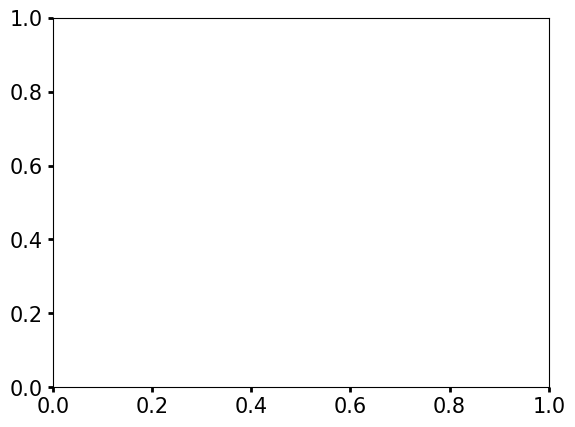

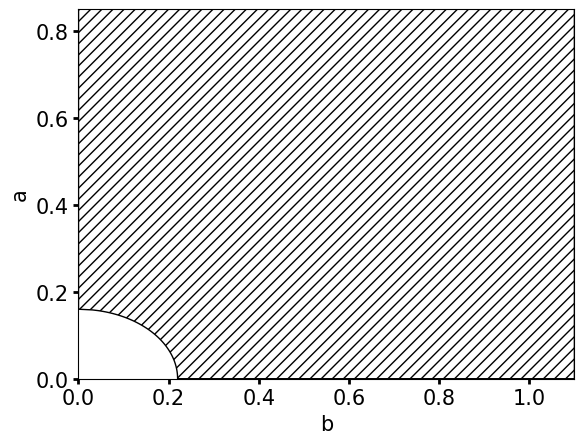

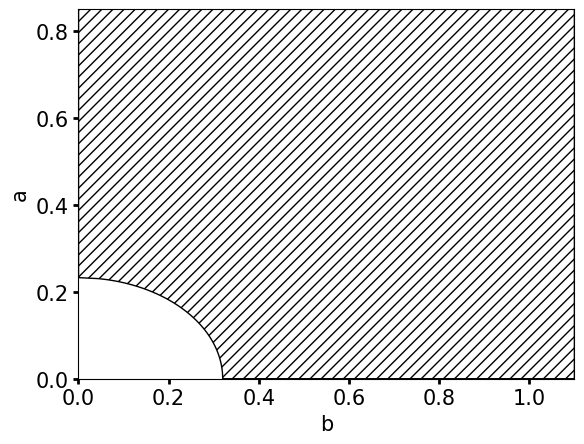

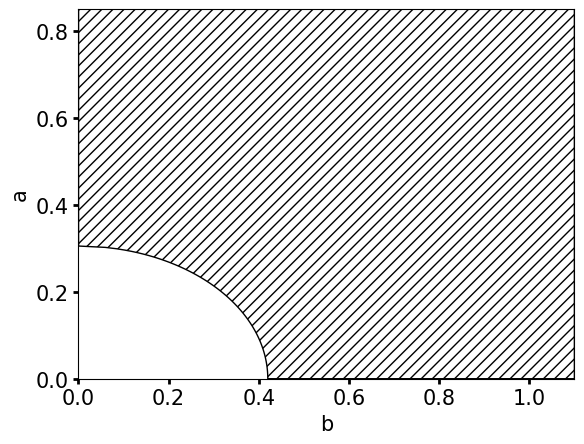

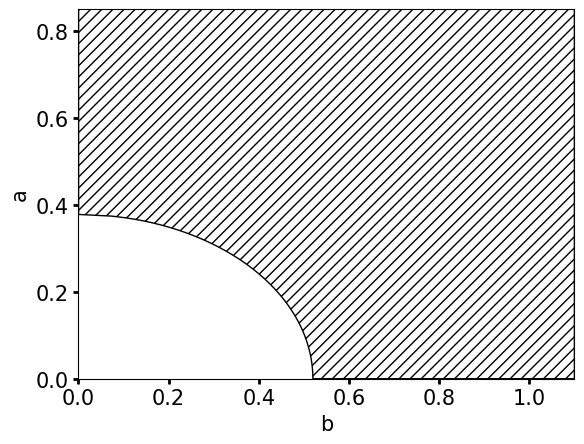

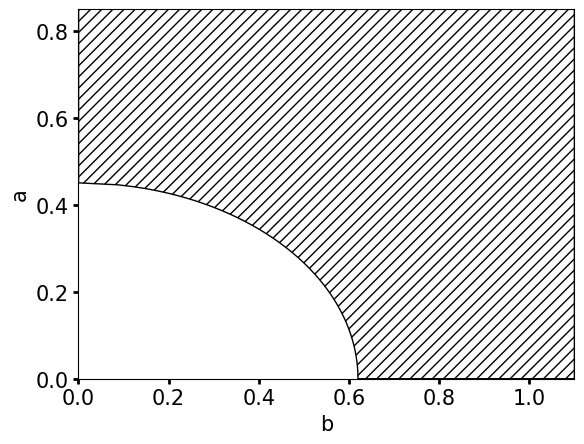

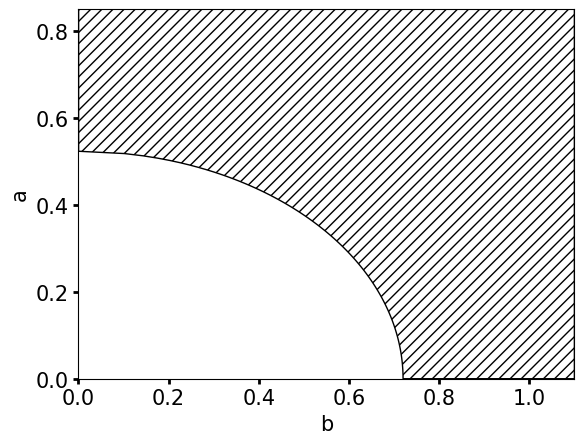

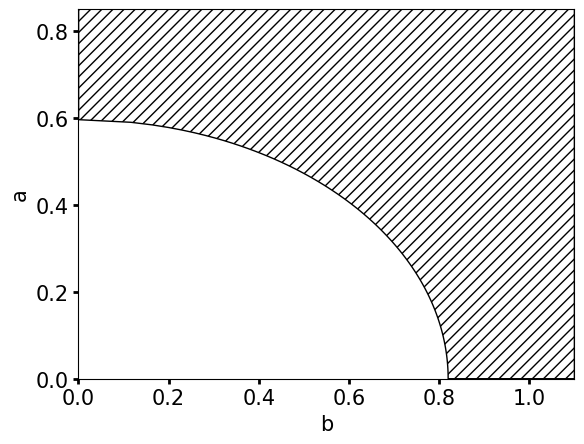

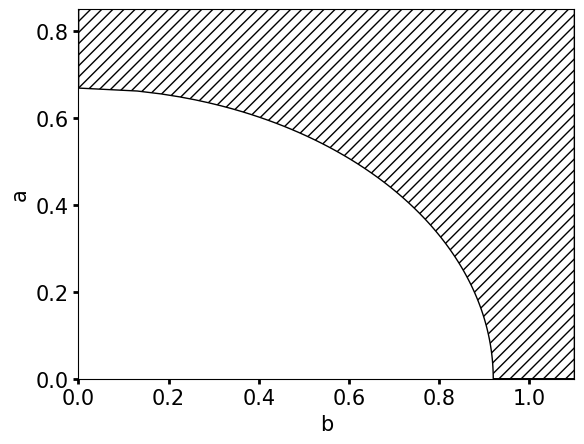

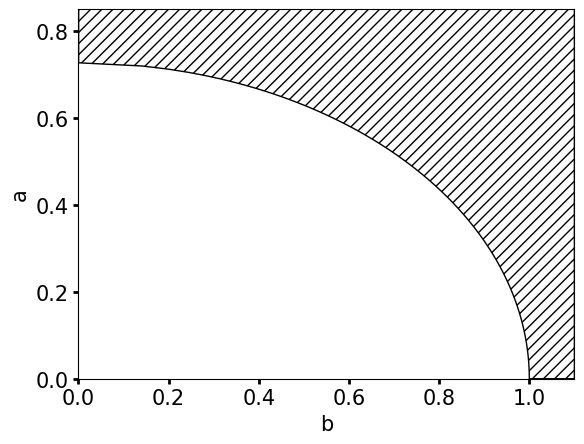

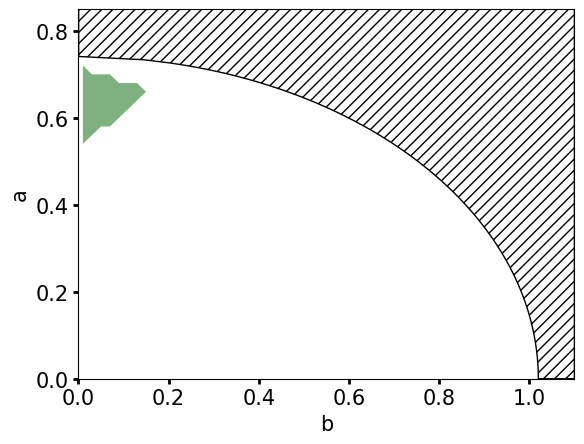

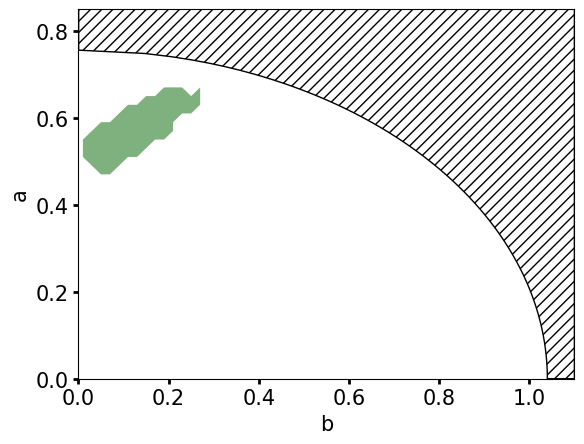

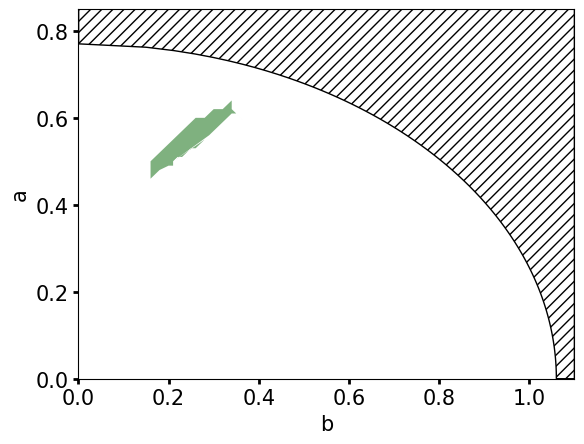

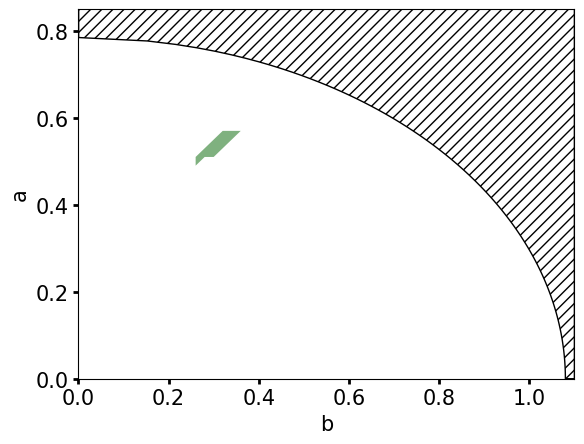

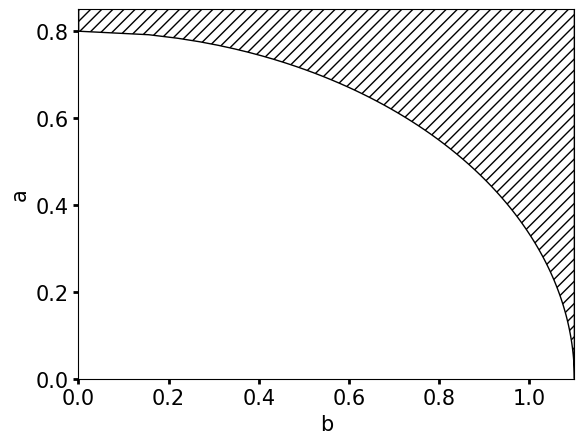

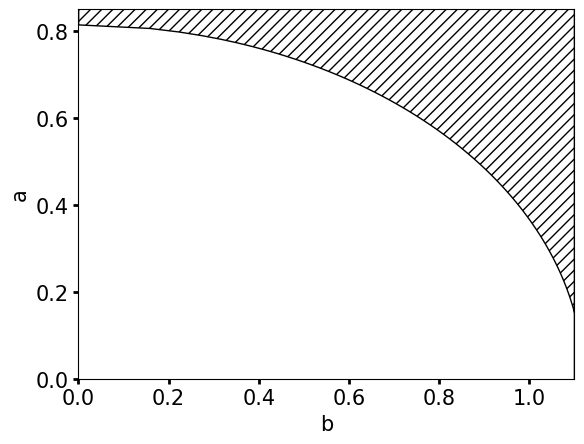

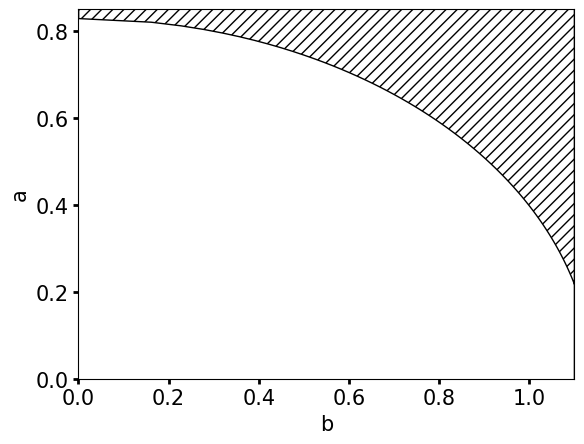

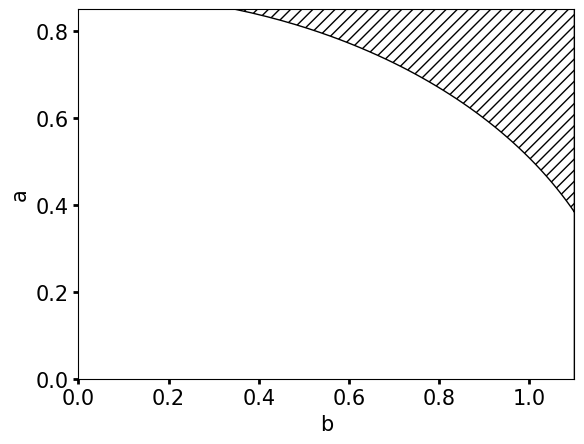

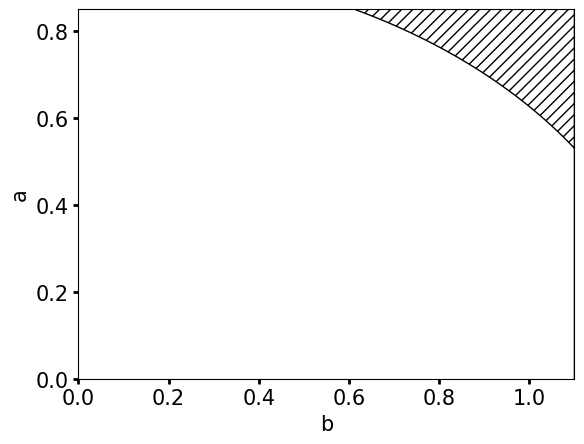

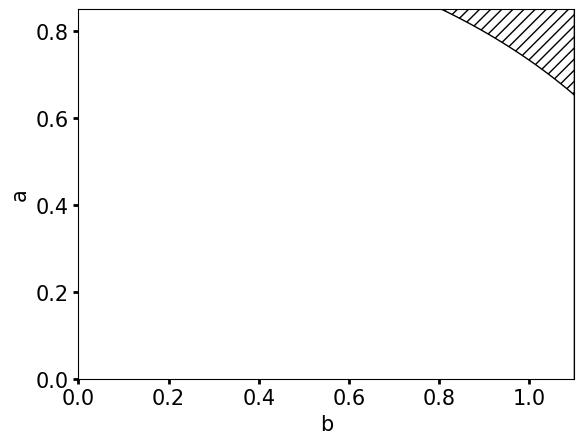

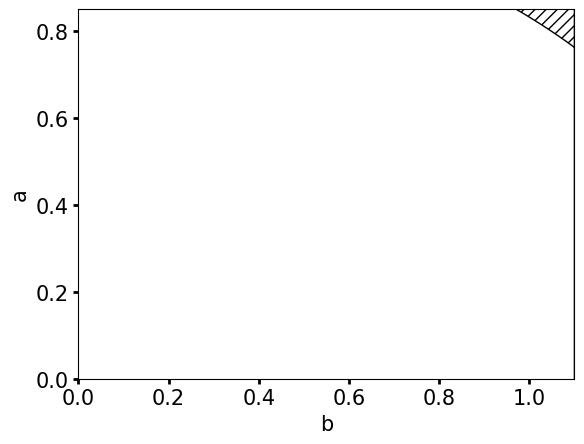

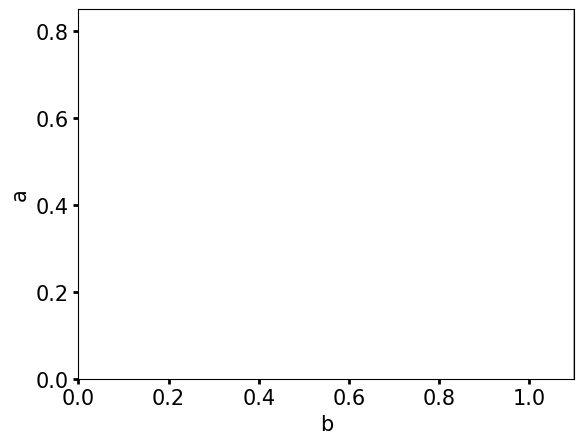

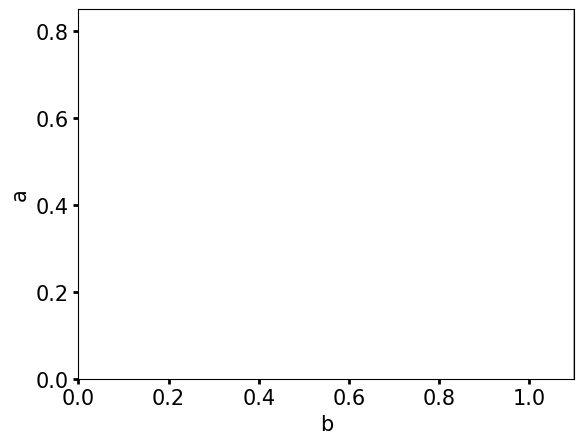

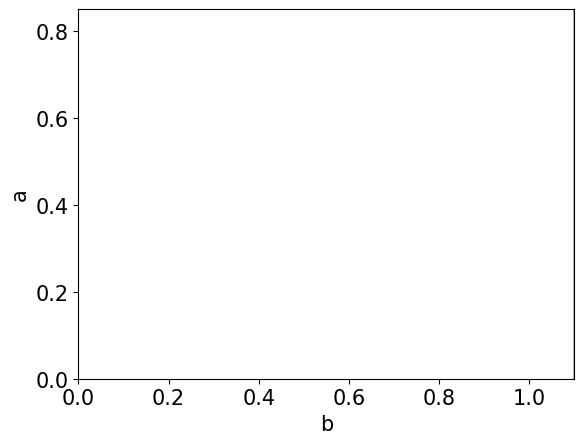

In [77]:
for dist in all_dist[1:]:
    dist_yes_mask = (yes[:,0] == dist)
    dist_maybe_mask = (maybe[:,0] == dist)
    dist_no_third_mask = (no_third[:,0] == dist)
    dist_no_mask = (no[:,0] == dist)
    dist_wrong_mask = (wrong[:,0] == dist)
    dist_failed_mask = (failed[:,0] == dist)

    yes_dist = yes[dist_yes_mask]
    yes_dist_append = np.vstack((yes_dist,yes_dist[0:1,:]))

    plt.rcParams.update({'font.size':15})
    plt.tick_params(axis='both', width=2)

    print(dist)
    fig = plt.figure()
    ax = fig.add_subplot(111)

    parameters_temp = all_parameters_moore[all_parameters_moore[:,0] == dist]
    
    parameters_temp_yes = parameters_temp[parameters_temp[:,3] == 1]
    parameters_temp_yes_append = np.vstack((parameters_temp_yes,parameters_temp_yes[0:1,:]))
    
    parameters_temp_no = parameters_temp[parameters_temp[:,3] == 0]

    xlim_max = 1.1
    ylim_max = 0.85

    alpha12 = np.pi/n_ellipses
    max_length = dist * np.tan(alpha12)-0.0000001
    length_linspace = np.linspace(max_length,0,100, endpoint=True)
    length_full_plot = np.concatenate((length_linspace, np.zeros((100))))
    
    width_linspace = calculate_width_maximum_width_of_ellipses(n_ellipses, dist, length_linspace)
    
    width_full_plot = np.concatenate((width_linspace, np.linspace(width_linspace[-1],xlim_max, 100)))

    plt.fill_between(width_full_plot, length_full_plot, ylim_max, facecolor='None',
    hatch='///',
    edgecolor='black',
    label='invalid / not tested')
    
    plt.fill(parameters_temp_yes_append[:,1], parameters_temp_yes_append[:,2], facecolor='darkgreen',
    alpha=0.5,
    label='valid region')
    
    ax.set_xlabel("b")
    ax.set_ylabel("a")
    
    plt.xlim(0,xlim_max)
    plt.ylim(0,ylim_max)
    #ax.legend()

plt.show()

0.22
Plots_parametersets_5_ellipses/Parametersets_5_ellipses_distance_0_22.eps


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


0.32
Plots_parametersets_5_ellipses/Parametersets_5_ellipses_distance_0_32.eps
0.42
Plots_parametersets_5_ellipses/Parametersets_5_ellipses_distance_0_42.eps
0.52
Plots_parametersets_5_ellipses/Parametersets_5_ellipses_distance_0_52.eps


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


0.62
Plots_parametersets_5_ellipses/Parametersets_5_ellipses_distance_0_62.eps
0.72
Plots_parametersets_5_ellipses/Parametersets_5_ellipses_distance_0_72.eps
0.82
Plots_parametersets_5_ellipses/Parametersets_5_ellipses_distance_0_82.eps


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


... (5 outputs left out)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


1.32
Plots_parametersets_5_ellipses/Parametersets_5_ellipses_distance_1_32.eps
1.42
Plots_parametersets_5_ellipses/Parametersets_5_ellipses_distance_1_42.eps
1.52
Plots_parametersets_5_ellipses/Parametersets_5_ellipses_distance_1_52.eps
1.62
Plots_parametersets_5_ellipses/Parametersets_5_ellipses_distance_1_62.eps
1.72
Plots_parametersets_5_ellipses/Parametersets_5_ellipses_distance_1_72.eps


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


1.82
Plots_parametersets_5_ellipses/Parametersets_5_ellipses_distance_1_82.eps


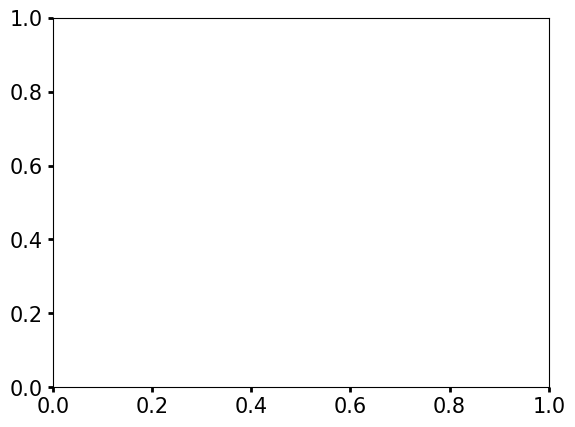

In [78]:
for dist in all_dist[1:]:
    dist_yes_mask = (yes[:,0] == dist)
    dist_maybe_mask = (maybe[:,0] == dist)
    dist_no_third_mask = (no_third[:,0] == dist)
    dist_no_mask = (no[:,0] == dist)
    dist_wrong_mask = (wrong[:,0] == dist)
    dist_failed_mask = (failed[:,0] == dist)

    yes_dist = yes[dist_yes_mask]
    yes_dist_append = np.vstack((yes_dist,yes_dist[0:1,:]))

    plt.rcParams.update({'font.size':15})
    plt.tick_params(axis='both', width=2)
    
    print(dist)
    fig = plt.figure()
    ax = fig.add_subplot(111)
    
    parameters_temp = all_parameters_moore[all_parameters_moore[:,0] == dist]
    
    parameters_temp_yes = parameters_temp[parameters_temp[:,3] == 1]
    parameters_temp_yes_append = np.vstack((parameters_temp_yes,parameters_temp_yes[0:1,:]))
    
    parameters_temp_no = parameters_temp[parameters_temp[:,3] == 0]
    
    xlim_max = 1.1
    ylim_max = 0.85

    
    alpha12 = np.pi/n_ellipses
    max_length = dist * np.tan(alpha12)-0.0000001
    length_linspace = np.linspace(max_length,0,100, endpoint=True)
    length_full_plot = np.concatenate((length_linspace, np.zeros((100))))
    
    width_linspace = calculate_width_maximum_width_of_ellipses(n_ellipses, dist, length_linspace)
    
    width_full_plot = np.concatenate((width_linspace, np.linspace(width_linspace[-1],xlim_max, 100)))
    
    plt.fill_between(width_full_plot, length_full_plot, ylim_max, facecolor='None',
    hatch='///',
    edgecolor='black',
    label='invalid / not tested')
    
    plt.fill(parameters_temp_yes_append[:,1], parameters_temp_yes_append[:,2], facecolor='darkgreen',
    alpha=0.5,
    label='valid region')
    
    ax.set_xlabel("b")
    ax.set_ylabel("a")
    plt.xlim(0,xlim_max)
    plt.ylim(0,ylim_max)
    
    os.makedirs("Plots_parametersets_5_ellipses", exist_ok = True)
    filename = f"Plots_parametersets_5_ellipses/Parametersets_5_ellipses_distance_{str(dist).replace('.', '_')}.eps"
    print(filename)
    plt.savefig(filename,dpi=300)
    plt.close()

plt.show()